In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

# Import standard libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import itertools  # Used later for the confusion matrix plot

# Import scikit-learn libraries for preprocessing, modeling, and evaluation
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, accuracy_score, roc_auc_score, roc_curve


# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

/kaggle/input/telco-customer-churn/WA_Fn-UseC_-Telco-Customer-Churn.csv


In [2]:
df = pd.read_csv("/kaggle/input/telco-customer-churn/WA_Fn-UseC_-Telco-Customer-Churn.csv")

# Inspect the first few rows of the dataset
df.head()


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
# 1. Drop the customer identifier column, since it is not used for prediction.
if 'customerID' in df.columns:
    df.drop('customerID', axis=1, inplace=True)

# 2. Convert TotalCharges to numeric. In case there are any non-numeric entries, they become NaN.
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
# Fill any missing values with the median
df['TotalCharges'] = df['TotalCharges'].fillna(df['TotalCharges'].median())

# 3. Map binary columns ('Yes'/'No') to 1/0.
binary_cols = ['Partner', 'Dependents', 'PhoneService', 'PaperlessBilling', 'Churn']
for col in binary_cols:
    # Strip extra whitespace and ensure proper case for a robust mapping
    df[col] = df[col].astype(str).str.strip().map({'Yes': 1, 'No': 0})

# 4. The SeniorCitizen column is already numeric (0 or 1).

df['SeniorCitizen'] = pd.to_numeric(df['SeniorCitizen'], errors='coerce')

# 5. Identify and one-hot encode the remaining categorical columns.
categorical_cols = ['gender', 'MultipleLines', 'InternetService', 'OnlineSecurity', 
                    'OnlineBackup', 'DeviceProtection', 'TechSupport', 
                    'StreamingTV', 'StreamingMovies', 'Contract', 'PaymentMethod']
                    
# One-hot encode these columns. drop_first=True avoids redundancy.
df = pd.get_dummies(df, columns=categorical_cols, drop_first=True)

# 6. Standardize numerical features.
#    We standardize MonthlyCharges and TotalCharges.
scaler = StandardScaler()
num_cols = ['MonthlyCharges', 'TotalCharges']  # Add 'tenure' if you want to standardize it as well.
df[num_cols] = scaler.fit_transform(df[num_cols])

# View the processed dataframe summary.
pd.options.display.max_columns = None
print("Processed DataFrame preview:")
print(df.head())

# Verify that all columns are numeric:
print("Data types after preprocessing:")
print(df.dtypes)


Processed DataFrame preview:
   SeniorCitizen  Partner  Dependents  tenure  PhoneService  PaperlessBilling  \
0              0        1           0       1             0                 1   
1              0        0           0      34             1                 0   
2              0        0           0       2             1                 1   
3              0        0           0      45             0                 0   
4              0        0           0       2             1                 1   

   MonthlyCharges  TotalCharges  Churn  gender_Male  \
0       -1.160323     -0.994242      0        False   
1       -0.259629     -0.173244      0         True   
2       -0.362660     -0.959674      1         True   
3       -0.746535     -0.194766      0         True   
4        0.197365     -0.940470      1        False   

   MultipleLines_No phone service  MultipleLines_Yes  \
0                            True              False   
1                           False        

In [ ]:
# Outlier detection using Z-score
num_cols = ['MonthlyCharges', 'TotalCharges', 'tenure']
# Calculate Z-scores
z_scores = np.abs(zscore(df[num_cols]))
# Identify outliers (Z-score > 3)
outliers = df[(z_scores > 3).any(axis=1)]
# Display summary of outliers
print(f"Number of outliers (|Z-score| > 3): {len(outliers)}")

# Boxplots for numerical features
plt.figure(figsize=(15, 5))
for i, col in enumerate(num_cols, 1):
    plt.subplot(1, 3, i)  
    sns.boxplot(data=df, y=col)
    plt.title(f'Boxplot of {col}')
plt.tight_layout()
plt.show()

In [4]:
# Define features (X) and target (y)
X = df.drop('Churn', axis=1)
y = df['Churn']

# Split into training (80%) and testing (20%) sets.
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)

print("Training features shape:", X_train.shape)
print("Testing features shape:", X_test.shape)


Training features shape: (5634, 30)
Testing features shape: (1409, 30)


In [5]:
# Initialize the Logistic Regression model. Decision tree, NB
# Import the necessary classes from scikit-learn
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB

from sklearn.metrics import accuracy_score, roc_auc_score, confusion_matrix

lr_model = LogisticRegression(random_state=42, max_iter=1000)
dt_model = DecisionTreeClassifier(random_state=42)
nb_model = GaussianNB()

# Train (fit) the model using the training data.
lr_model.fit(X_train, y_train)
dt_model.fit(X_train, y_train)
nb_model.fit(X_train, y_train)


# Make predictions on the test set for each model.
y_pred_lr = lr_model.predict(X_test)
y_pred_dt = dt_model.predict(X_test)
y_pred_nb = nb_model.predict(X_test)

# Get predicted probabilities for the positive class (churn) for each model.
y_prob_lr = lr_model.predict_proba(X_test)[:, 1]
y_prob_dt = dt_model.predict_proba(X_test)[:, 1]
y_prob_nb = nb_model.predict_proba(X_test)[:, 1]

print("Model training complete.")

# Evaluate performance for each model.
accuracy_lr = accuracy_score(y_test, y_pred_lr)
accuracy_dt = accuracy_score(y_test, y_pred_dt)
accuracy_nb = accuracy_score(y_test, y_pred_nb)

auc_lr = roc_auc_score(y_test, y_prob_lr)
auc_dt = roc_auc_score(y_test, y_prob_dt)
auc_nb = roc_auc_score(y_test, y_prob_nb)

# Print the evaluation results.
print("Logistic Regression Accuracy: {:.4f}, ROC-AUC: {:.4f}".format(accuracy_lr, auc_lr))
print("Decision Tree Accuracy:     {:.4f}, ROC-AUC: {:.4f}".format(accuracy_dt, auc_dt))
print("Naive Bayes Accuracy:       {:.4f}, ROC-AUC: {:.4f}".format(accuracy_nb, auc_nb))

# print confusion matrices for further insight.
print("Logistic Regression Confusion Matrix:\n", confusion_matrix(y_test, y_pred_lr))
print("Decision Tree Confusion Matrix:\n", confusion_matrix(y_test, y_pred_dt))
print("Naive Bayes Confusion Matrix:\n", confusion_matrix(y_test, y_pred_nb))


Model training complete.
Logistic Regression Accuracy: 0.8211, ROC-AUC: 0.8622
Decision Tree Accuracy:     0.7140, ROC-AUC: 0.6388
Naive Bayes Accuracy:       0.6657, ROC-AUC: 0.8377
Logistic Regression Confusion Matrix:
 [[934 102]
 [150 223]]
Decision Tree Confusion Matrix:
 [[828 208]
 [195 178]]
Naive Bayes Confusion Matrix:
 [[605 431]
 [ 40 333]]


In [6]:
# extension of the above to include SVM and Random Forest (just as an extra to compare models within same category)
# Import the necessary classes from scikit-learn
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, roc_auc_score, confusion_matrix

# Initialize the models.
lr_model = LogisticRegression(random_state=42, max_iter=1000)
dt_model = DecisionTreeClassifier(random_state=42)
nb_model = GaussianNB()
rf_model = RandomForestClassifier(random_state=42, n_estimators=100)
svm_model = SVC(probability=True, random_state=42)  # Set probability=True to enable predict_proba

# Train (fit) each model using the training data.
lr_model.fit(X_train, y_train)
dt_model.fit(X_train, y_train)
nb_model.fit(X_train, y_train)
rf_model.fit(X_train, y_train)
svm_model.fit(X_train, y_train)

# Make predictions on the test set for each model.
y_pred_lr = lr_model.predict(X_test)
y_pred_dt = dt_model.predict(X_test)
y_pred_nb = nb_model.predict(X_test)
y_pred_rf = rf_model.predict(X_test)
y_pred_svm = svm_model.predict(X_test)

# Get predicted probabilities for the positive class (churn) for each model.
y_prob_lr = lr_model.predict_proba(X_test)[:, 1]
y_prob_dt = dt_model.predict_proba(X_test)[:, 1]
y_prob_nb = nb_model.predict_proba(X_test)[:, 1]
y_prob_rf = rf_model.predict_proba(X_test)[:, 1]
y_prob_svm = svm_model.predict_proba(X_test)[:, 1]

print("Model training complete.")

# Evaluate performance for each model.
accuracy_lr = accuracy_score(y_test, y_pred_lr)
accuracy_dt = accuracy_score(y_test, y_pred_dt)
accuracy_nb = accuracy_score(y_test, y_pred_nb)
accuracy_rf = accuracy_score(y_test, y_pred_rf)
accuracy_svm = accuracy_score(y_test, y_pred_svm)

auc_lr = roc_auc_score(y_test, y_prob_lr)
auc_dt = roc_auc_score(y_test, y_prob_dt)
auc_nb = roc_auc_score(y_test, y_prob_nb)
auc_rf = roc_auc_score(y_test, y_prob_rf)
auc_svm = roc_auc_score(y_test, y_prob_svm)

# Print the evaluation results.
print("Logistic Regression Accuracy: {:.4f}, ROC-AUC: {:.4f}".format(accuracy_lr, auc_lr))
print("Decision Tree Accuracy:     {:.4f}, ROC-AUC: {:.4f}".format(accuracy_dt, auc_dt))
print("Naive Bayes Accuracy:       {:.4f}, ROC-AUC: {:.4f}".format(accuracy_nb, auc_nb))
print("Random Forest Accuracy:     {:.4f}, ROC-AUC: {:.4f}".format(accuracy_rf, auc_rf))
print("SVM Accuracy:               {:.4f}, ROC-AUC: {:.4f}".format(accuracy_svm, auc_svm))

# Print confusion matrices for further insight.
print("Logistic Regression Confusion Matrix:\n", confusion_matrix(y_test, y_pred_lr))
print("Decision Tree Confusion Matrix:\n", confusion_matrix(y_test, y_pred_dt))
print("Naive Bayes Confusion Matrix:\n", confusion_matrix(y_test, y_pred_nb))
print("Random Forest Confusion Matrix:\n", confusion_matrix(y_test, y_pred_rf))
print("SVM Confusion Matrix:\n", confusion_matrix(y_test, y_pred_svm))


Model training complete.
Logistic Regression Accuracy: 0.8211, ROC-AUC: 0.8622
Decision Tree Accuracy:     0.7140, ROC-AUC: 0.6388
Naive Bayes Accuracy:       0.6657, ROC-AUC: 0.8377
Random Forest Accuracy:     0.7999, ROC-AUC: 0.8374
SVM Accuracy:               0.7928, ROC-AUC: 0.8258
Logistic Regression Confusion Matrix:
 [[934 102]
 [150 223]]
Decision Tree Confusion Matrix:
 [[828 208]
 [195 178]]
Naive Bayes Confusion Matrix:
 [[605 431]
 [ 40 333]]
Random Forest Confusion Matrix:
 [[948  88]
 [194 179]]
SVM Confusion Matrix:
 [[953  83]
 [209 164]]


In [7]:
# For Logistic Regression model:
y_prob_lr = lr_model.predict_proba(X_test)[:, 1]  # get predicted probability for 'churn' class
y_prob_percentage_lr = y_prob_lr * 100            # convert probabilities to percentages

print("Logistic Regression predictions:")
for i, prob in enumerate(y_prob_percentage_lr[:5]):
    print(f"Customer {i} is predicted to have a {prob:.2f}% likelihood to churn (Logistic Regression)")


#For Decision Tree and Naive Bayes, we decided it was better to make it a hard yes or no
# For Decision Tree model:
y_prob_dt = dt_model.predict_proba(X_test)[:, 1]
# Convert probabilities to hard decisions: "Yes" if probability >= 0.5 else "No"
y_pred_hard_dt = ["Yes" if prob >= 0.5 else "No" for prob in y_prob_dt]

print("\nDecision Tree hard predictions:")
for i, pred in enumerate(y_pred_hard_dt[:5]):
    print(f"Customer {i} is predicted to churn: {pred} (Decision Tree)")

# For Naive Bayes model:
y_prob_nb = nb_model.predict_proba(X_test)[:, 1]
# Convert probabilities to hard decisions: "Yes" if probability >= 0.5 else "No"
y_pred_hard_nb = ["Yes" if prob >= 0.5 else "No" for prob in y_prob_nb]

print("\nNaive Bayes hard predictions:")
for i, pred in enumerate(y_pred_hard_nb[:5]):
    print(f"Customer {i} is predicted to churn: {pred} (Naive Bayes)")



Logistic Regression predictions:
Customer 0 is predicted to have a 69.57% likelihood to churn (Logistic Regression)
Customer 1 is predicted to have a 5.94% likelihood to churn (Logistic Regression)
Customer 2 is predicted to have a 0.44% likelihood to churn (Logistic Regression)
Customer 3 is predicted to have a 61.08% likelihood to churn (Logistic Regression)
Customer 4 is predicted to have a 0.58% likelihood to churn (Logistic Regression)

Decision Tree hard predictions:
Customer 0 is predicted to churn: Yes (Decision Tree)
Customer 1 is predicted to churn: Yes (Decision Tree)
Customer 2 is predicted to churn: No (Decision Tree)
Customer 3 is predicted to churn: No (Decision Tree)
Customer 4 is predicted to churn: No (Decision Tree)

Naive Bayes hard predictions:
Customer 0 is predicted to churn: Yes (Naive Bayes)
Customer 1 is predicted to churn: No (Naive Bayes)
Customer 2 is predicted to churn: No (Naive Bayes)
Customer 3 is predicted to churn: Yes (Naive Bayes)
Customer 4 is pred

Logistic Regression Evaluation:
Accuracy: 0.8211497515968772
Confusion Matrix:
 [[934 102]
 [150 223]]
AUC ROC Score: 0.8622498887244197
Classification Report:
               precision    recall  f1-score   support

           0       0.86      0.90      0.88      1036
           1       0.69      0.60      0.64       373

    accuracy                           0.82      1409
   macro avg       0.77      0.75      0.76      1409
weighted avg       0.82      0.82      0.82      1409



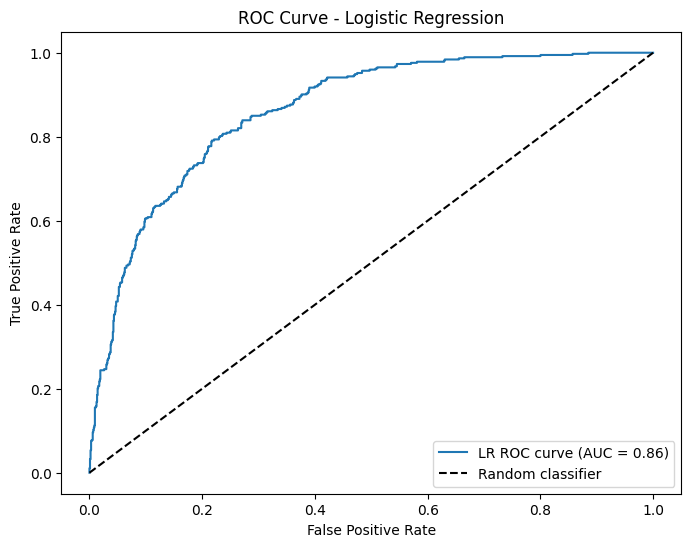

Decision Tree Evaluation:
Accuracy: 0.7139815471965933
Confusion Matrix:
 [[828 208]
 [195 178]]
AUC ROC Score: 0.6387878207583302
Classification Report:
               precision    recall  f1-score   support

           0       0.81      0.80      0.80      1036
           1       0.46      0.48      0.47       373

    accuracy                           0.71      1409
   macro avg       0.64      0.64      0.64      1409
weighted avg       0.72      0.71      0.72      1409



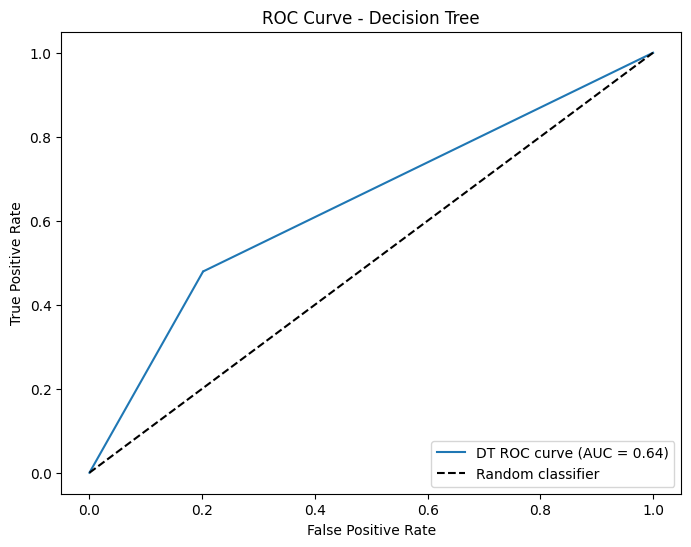

Naive Bayes Evaluation:
Accuracy: 0.6657203690560681
Confusion Matrix:
 [[605 431]
 [ 40 333]]
AUC ROC Score: 0.8377252683552951
Classification Report:
               precision    recall  f1-score   support

           0       0.94      0.58      0.72      1036
           1       0.44      0.89      0.59       373

    accuracy                           0.67      1409
   macro avg       0.69      0.74      0.65      1409
weighted avg       0.81      0.67      0.68      1409



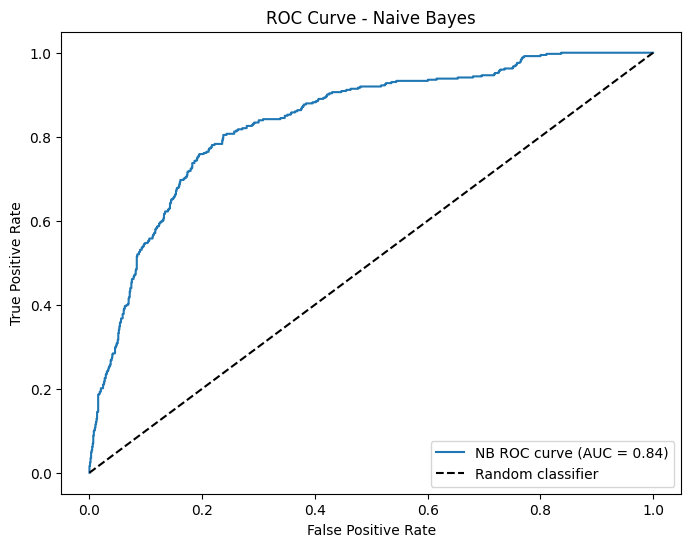

In [8]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import accuracy_score, confusion_matrix, roc_auc_score, roc_curve, classification_report

##############################
# Logistic Regression Metrics
##############################
accuracy_lr = accuracy_score(y_test, y_pred_lr)
cm_lr = confusion_matrix(y_test, y_pred_lr)
auc_lr = roc_auc_score(y_test, y_prob_lr)

print("Logistic Regression Evaluation:")
print("Accuracy:", accuracy_lr)
print("Confusion Matrix:\n", cm_lr)
print("AUC ROC Score:", auc_lr)
print("Classification Report:\n", classification_report(y_test, y_pred_lr))

# Plot ROC curve for Logistic Regression
fpr_lr, tpr_lr, thresholds_lr = roc_curve(y_test, y_prob_lr)
plt.figure(figsize=(8, 6))
plt.plot(fpr_lr, tpr_lr, label=f"LR ROC curve (AUC = {auc_lr:.2f})")
plt.plot([0, 1], [0, 1], 'k--', label="Random classifier")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Logistic Regression")
plt.legend(loc="lower right")
plt.show()

##############################
# Decision Tree Metrics
##############################
accuracy_dt = accuracy_score(y_test, y_pred_dt)
cm_dt = confusion_matrix(y_test, y_pred_dt)
auc_dt = roc_auc_score(y_test, y_prob_dt)

print("Decision Tree Evaluation:")
print("Accuracy:", accuracy_dt)
print("Confusion Matrix:\n", cm_dt)
print("AUC ROC Score:", auc_dt)
print("Classification Report:\n", classification_report(y_test, y_pred_dt))

# Plot ROC curve for Decision Tree
fpr_dt, tpr_dt, thresholds_dt = roc_curve(y_test, y_prob_dt)
plt.figure(figsize=(8, 6))
plt.plot(fpr_dt, tpr_dt, label=f"DT ROC curve (AUC = {auc_dt:.2f})")
plt.plot([0, 1], [0, 1], 'k--', label="Random classifier")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Decision Tree")
plt.legend(loc="lower right")
plt.show()

##############################
# Naive Bayes Metrics
##############################
accuracy_nb = accuracy_score(y_test, y_pred_nb)
cm_nb = confusion_matrix(y_test, y_pred_nb)
auc_nb = roc_auc_score(y_test, y_prob_nb)

print("Naive Bayes Evaluation:")
print("Accuracy:", accuracy_nb)
print("Confusion Matrix:\n", cm_nb)
print("AUC ROC Score:", auc_nb)
print("Classification Report:\n", classification_report(y_test, y_pred_nb))

# Plot ROC curve for Naive Bayes
fpr_nb, tpr_nb, thresholds_nb = roc_curve(y_test, y_prob_nb)
plt.figure(figsize=(8, 6))
plt.plot(fpr_nb, tpr_nb, label=f"NB ROC curve (AUC = {auc_nb:.2f})")
plt.plot([0, 1], [0, 1], 'k--', label="Random classifier")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Naive Bayes")
plt.legend(loc="lower right")
plt.show()


This model could have been more accurate if the dataset was more balanced. There are techniques that could be applied to overcome this issue, however this is out of scope currently. 